In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [56]:
url = "https://raw.githubusercontent.com/NastyaPoleshuk/PythonProject/refs/heads/master/club_bookings.csv"
df = pd.read_csv(url)
df["Дата"] = pd.to_datetime(df["Дата"])

print("Размер таблицы:", df.shape)
print(df.head())
print(df.tail())
print("\n")
print(df["Статус услуги"].value_counts())

Размер таблицы: (2500, 8)
   ID       Дата День недели  Время                    Услуга  Цена  \
0   1 2026-01-01     Четверг     16  Занятие по абонементу(8)  1400   
1   2 2026-01-01     Четверг     19  Занятие по абонементу(8)  1400   
2   3 2026-01-01     Четверг     16  Занятие по абонементу(8)  1400   
3   4 2026-01-01     Четверг     15  Занятие по абонементу(4)  1500   
4   5 2026-01-01     Четверг     12           Разовое занятие  1600   

             Клиент Статус услуги  
0  Спортсмен (клуб)    Состоялась  
1  Спортсмен (клуб)    Состоялась  
2  Спортсмен (клуб)    Состоялась  
3  Спортсмен (клуб)    Состоялась  
4  Спортсмен (клуб)    Состоялась  
        ID       Дата  День недели  Время                       Услуга  Цена  \
2495  2496 2026-10-25  Воскресенье     10  Аренда лошади на фотосессию  2000   
2496  2497 2026-10-27      Вторник     19     Занятие по абонементу(8)  1500   
2497  2498 2026-10-27      Вторник     18     Занятие по абонементу(8)  1500   
2498  2499 

In [66]:
prices_done = done["Цена"].to_numpy()
print(f"Средняя стоимость записи: {np.mean(prices_done):.0f} руб.")
print(f"Медианная стоимость записи: {np.median(prices_done):.0f} руб.")

Средняя стоимость записи: 1482 руб.
Медианная стоимость записи: 1500 руб.


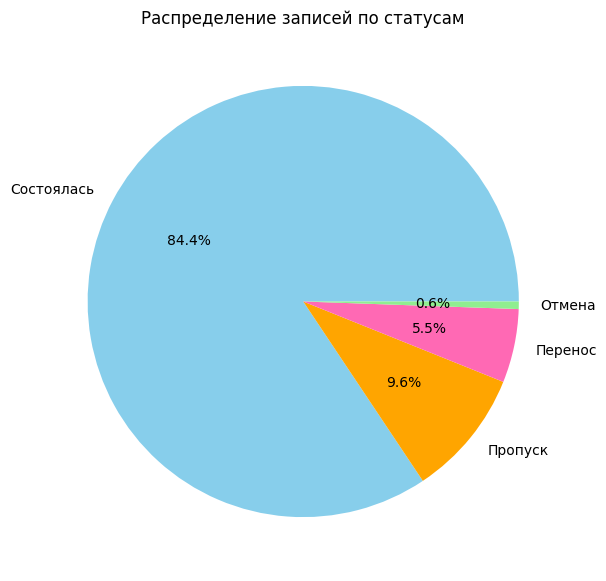

In [42]:
status_counts = df["Статус услуги"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(status_counts, labels=status_counts.index, autopct="%1.1f%%", colors=["skyblue", "orange", "hotpink", "lightgreen"])
plt.title("Распределение записей по статусам")
plt.show()

Из 2 500 записей состоялось 2 109 (84,4%), пропущено клиентами - 239 (9,6%), перенесено - 138 (5,5%), отменено - 14 (0,6%). Таким образом, около 15% записей не доходят до занятия, главным образом из-за пропусков.

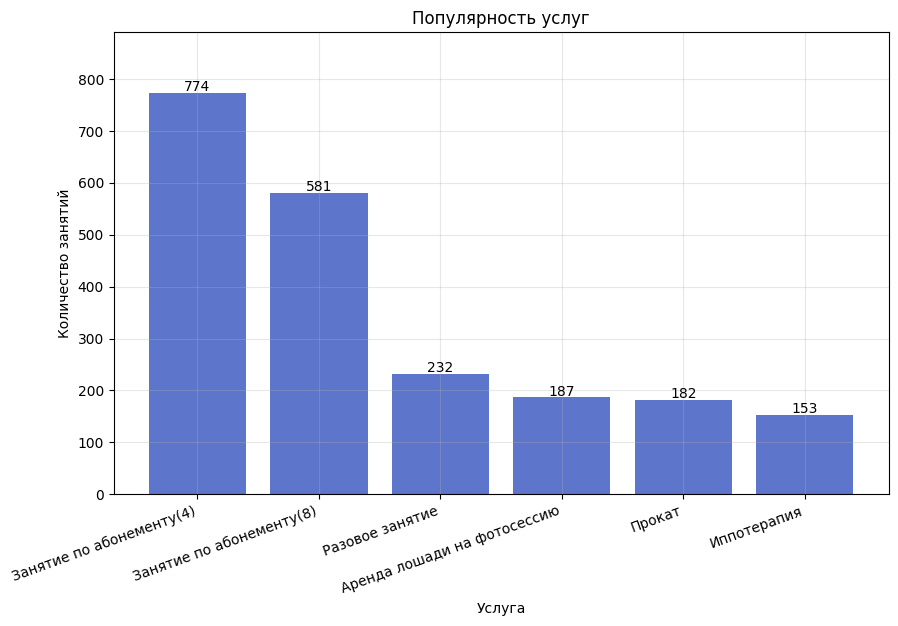

In [43]:
done = df[df["Статус услуги"] == "Состоялась"]
counts = done["Услуга"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(counts.index, counts, color="#5d76cb")
plt.title("Популярность услуг")
plt.xlabel("Услуга")
plt.ylabel("Количество занятий")
plt.ylim(0, counts.max() * 1.15)
plt.xticks(rotation=20, ha="right")
plt.grid(alpha=0.3)
for i in range(len(counts)):
    plt.text(counts.index[i], counts.iloc[i] + 3, f"{counts.iloc[i]}", ha="center")
plt.show()

Самая популярная услуга - "Занятие по абонементу(4)" (774 занятия), следом "Занятие по абонементу(8)" (581). На схожем уровне поспросу находятся "разовое занятие"(232), "аренда лошади на фотоссесию" (187) и "прокат" (182), тем не менее разовое занятие лидирует. Самая редкая услуга - "Иппотерапия" (153). Таким образом, основу спроса формируют классические тренировки, а именно абонементы.

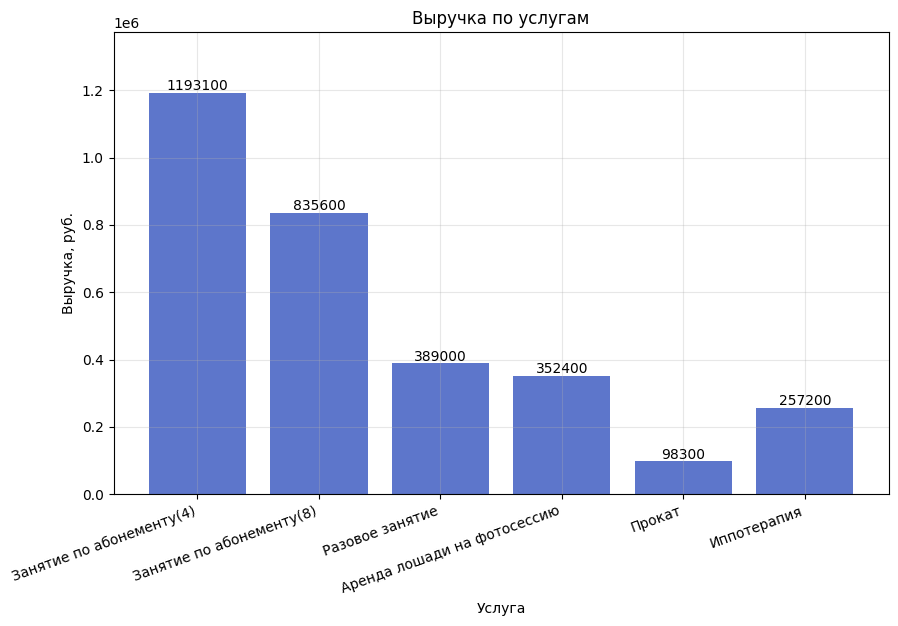

In [44]:
revenue = done.groupby("Услуга")["Цена"].sum().reindex(counts.index)

plt.figure(figsize=(10, 6))
plt.bar(revenue.index, revenue, color="#5d76cb")
plt.title("Выручка по услугам")
plt.xlabel("Услуга")
plt.ylabel("Выручка, руб.")
plt.ylim(0, revenue.max() * 1.15)
plt.xticks(rotation=20, ha="right")
plt.grid(alpha=0.3)
for i in range(len(revenue)):
    plt.text(revenue.index[i], revenue.iloc[i] + 8000, f"{revenue.iloc[i]}", ha="center")
plt.show()

Больше всего приносит абонемент на 4 занятия (1193100), в то время как превосходящий по спросу иппотерапию прокат приносит 98300, что более чем в два раза меньше выручки от иппотерапии (257200). Разовое занятие и аренда лошади на фотосессию почти одинаково прибыльны (389000-352400)

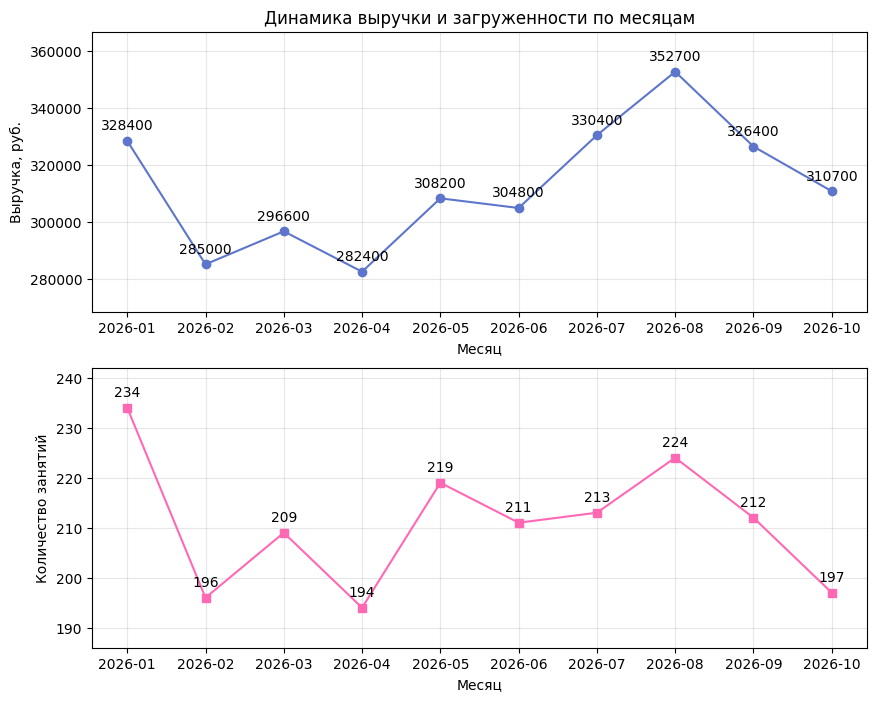

In [64]:
months = done["Дата"].dt.to_period("M").astype(str)
monthly = done.groupby(months)["Цена"].sum()
monthly_humans = done.groupby(months).size()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(monthly.index, monthly, marker="o", color="#5d76cb")
ax1.set_title("Динамика выручки и загруженности по месяцам")
ax1.set_ylabel("Выручка, руб.")
ax1.grid(alpha=0.3)
ax1.set_xlabel("Месяц")
ax1.margins(y=0.2)
for x, y in monthly.items():
    ax1.annotate(y, (x, y), textcoords="offset points", xytext=(0, 8), ha="center")

ax2.plot(monthly_humans.index, monthly_humans, marker="s", color="hotpink")
ax2.set_xlabel("Месяц")
ax2.set_ylabel("Количество занятий")
ax2.grid(alpha=0.3)
ax2.margins(y=0.2)
for x, y in monthly_humans.items():
    ax2.annotate(y, (x, y), textcoords="offset points", xytext=(0, 8), ha="center")

plt.show()

Пик выручки - август, в то время как весной и под конец зимы выручка падает - это объясняется отстутсвием грунта для тренировок в межсезонье. Тем не меннее, разрыв между пиком (352700) и спадом (282400) составляет менее 80000, что позволяет говорить о востребованности спорта в любое время года. Также наблюдается повышенная посещаемость в период каникул и праздников (январь, май  и месяцы лета). Также в июле были повышены цены, что привело к временному уменьшению клиентов по сравнению с маем, но значительно увеличило выручку. Новость об изменении цен, размещённая на сайте заранее, могла бы сохранить часть клиентов, позволив им заранее приобрести абонемент по старой цене.

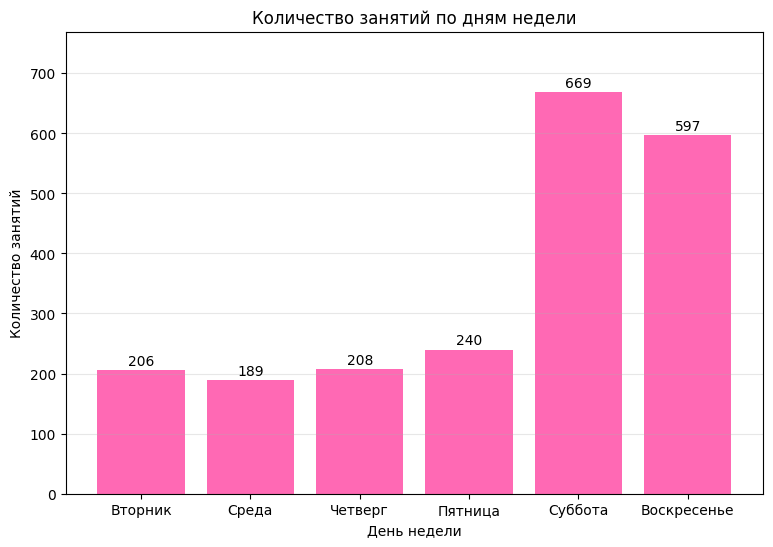

In [46]:
order = ["Вторник", "Среда", "Четверг", "Пятница", "Суббота", "Воскресенье"]
by_day = done["День недели"].value_counts().reindex(order)

plt.figure(figsize=(9, 6))
plt.bar(by_day.index, by_day, color="hotpink")
plt.title("Количество занятий по дням недели")
plt.xlabel("День недели")
plt.ylabel("Количество занятий")
plt.ylim(0, by_day.max() * 1.15)
plt.grid(axis="y", alpha=0.3)
for i in range(len(by_day)):
    plt.text(by_day.index[i], by_day.iloc[i] + 8, f"{by_day.iloc[i]}", ha="center")
plt.show()

Основная нагрузка приходится на выходные: суббота (669) и воскресенье (597) вместе — около 60% всех занятий. В будни - 189-240 занятий в день. Значит, в выходные клубу нужно больше лошадей и инструкторов.

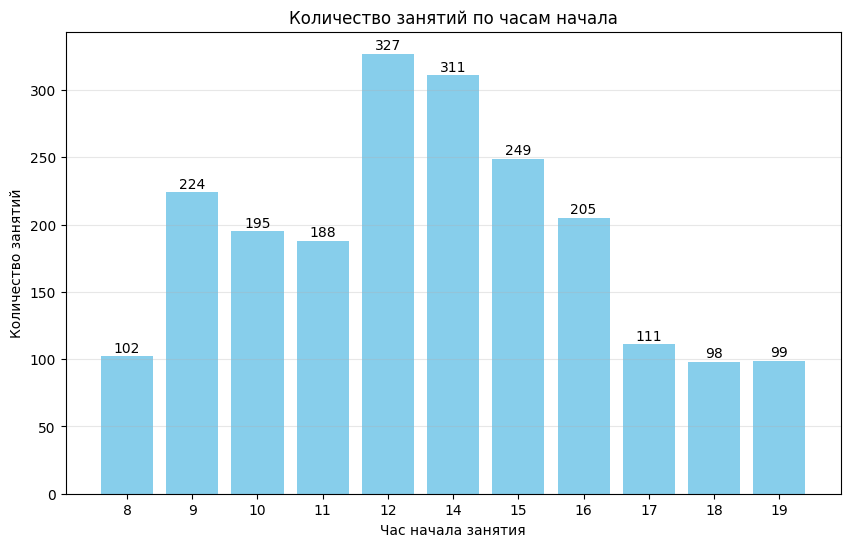

In [47]:
by_hour = done["Время"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(by_hour.index.astype(str), by_hour, color="skyblue")
plt.title("Количество занятий по часам начала")
plt.xlabel("Час начала занятия")
plt.ylabel("Количество занятий")
plt.grid(axis="y", alpha=0.3)
for i in range(len(by_hour)):
    plt.text(str(by_hour.index[i]), by_hour.iloc[i] + 3, f"{by_hour.iloc[i]}", ha="center")
plt.show()

Самое востребованное время - до обеда и после. Нагрузка в определенные дни и часы повышает риск ручных ошибок и накладок (например, при записи арендаторов лошадей), что решает онлайн-расписание на Flask.

Анализ актуальности проекта: из-за несостоявшихся занятий клуб теряет около 10% выручки. Напоминания и удобный перенос записи позволят вернуть хотя бы часть.

Онлайн-запись избавляет клиентов от звонков и переписки, а в личном кабинете видно число оставшихся занятий по абонементу. Выходные перегружены (в субботу и воскресенье проходит около 60% занятий), а сервис покажет свободные слоты в будни.

Все записи собираются в одном месте и не теряются.

Также сайт поможет развить интерес  к менее востребованным услугам, таким как аренда лошади на фотосессию и иппотерапия.